# Task 2b - Oversampling / data synthesis (adult census) (SMOTE)
AI use: Claude was used to guide the structure and understand some concepts that were quite confusing. I ran the code myself and checked the outputs.

In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
from imblearn.over_sampling import SMOTE, ADASYN

df = pd.read_csv("../../../Datasets/adult.csv")   
df = df.drop_duplicates()
df = df.replace("?", np.nan).dropna()

# SMOTE needs numeric features, so keep only these + the target
df = df[["age", "education.num", "hours.per.week", "race"]].reset_index(drop=True)


<Axes: >

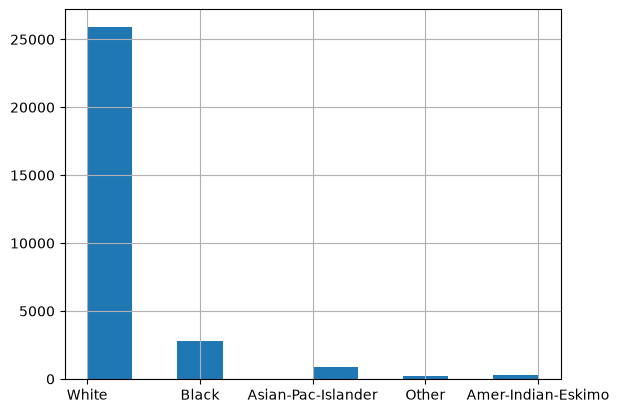

In [5]:
df["race"].hist()

In [4]:
df["race"].value_counts()

race
White                 25912
Black                  2816
Asian-Pac-Islander      894
Amer-Indian-Eskimo      286
Other                   231
Name: count, dtype: int64

In [8]:
target = "race"

X = df.drop(target, axis=1)
y = df[target]

# define sampling strategy
# NOTE! this is oversampling, you can go over the original limit
# because you are generating more data
# same target counts as in the SDV step
# oversampling: the rare groups go up to 600, the others stay as they are
strategy = {
    "White": 25912,
    "Black": 2816,
    "Asian-Pac-Islander": 894,
    "Amer-Indian-Eskimo": 600,
    "Other": 600,
}


# use SMOTE with default settings (often enough)
# model = SMOTE()
model = SMOTE(sampling_strategy=strategy, random_state=123)

# ADASYN is an alternative to SMOTE, but is often a bit trickier to
# use with custom sampling strategies, you can "auto" though
# model = ADASYN(sampling_strategy="auto", random_state=123)

X_resampled, y_resampled = model.fit_resample(X, y)

# reconstruct the dataframe
df_resampled = pd.DataFrame(X_resampled, columns=X.columns)
df_resampled[target] = y_resampled

In [6]:
df.shape

(30139, 4)

In [9]:
df_resampled.shape

(30822, 4)

<Axes: >

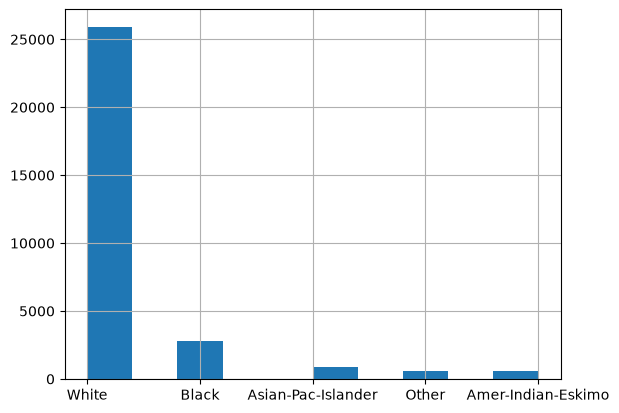

In [12]:
df_resampled["race"].hist()

In [11]:
df_resampled["race"].value_counts()

race
White                 25912
Black                  2816
Asian-Pac-Islander      894
Other                   600
Amer-Indian-Eskimo      600
Name: count, dtype: int64

In [13]:
df.describe()

,age,education.num,hours.per.week
count,30139.000000,30139.000000,30139.000000
mean,38.441720,10.122532,40.934703
std,13.131426,2.548738,11.978753
min,17.000000,1.000000,1.000000
25%,28.000000,9.000000,40.000000
50%,37.000000,10.000000,40.000000
75%,47.000000,13.000000,45.000000
max,90.000000,16.000000,99.000000


In [ ]:
# Pretty similar to the original dataset
df_resampled.describe()

,age,education.num,hours.per.week
count,30822.000000,30822.000000,30822.000000
mean,38.344105,10.091947,40.923334
std,13.100080,2.553674,11.956381
min,17.000000,1.000000,1.000000
25%,28.000000,9.000000,40.000000
50%,37.000000,10.000000,40.000000
75%,47.000000,12.000000,45.000000
max,90.000000,16.000000,99.000000


In [15]:
df.drop(columns="race").var()

age               172.434348
education.num       6.496068
hours.per.week    143.490527
dtype: float64

In [16]:
df_resampled.drop(columns="race").var()

age               171.612096
education.num       6.521249
hours.per.week    142.955058
dtype: float64

In [20]:
import phik

num_cols = ["age", "education.num", "hours.per.week"]
df.phik_matrix(interval_cols=num_cols)

,age,education.num,hours.per.week,race
age,1.000000,0.296713,0.419871,0.055974
education.num,0.296713,1.000000,0.279138,0.165847
hours.per.week,0.419871,0.279138,1.000000,0.143792
race,0.055974,0.165847,0.143792,1.000000


In [ ]:
df_resampled.phik_matrix(interval_cols=num_cols)

,age,education.num,hours.per.week,race
age,1.000000,0.294234,0.419145,0.094915
education.num,0.294234,1.000000,0.277967,0.202782
hours.per.week,0.419145,0.277967,1.000000,0.151454
race,0.094915,0.202782,0.151454,1.000000


### Conclusion

* I used SMOTE on the same problem as before: oversampling the rare race groups Amer-Indian-Eskimo and Other to 600 rows each . SMOTE creates new rows by interpolating between neighbouring rows of the same class(came to know with help of AI). It only works with numeric columns, so I used age, education.num and hours.per.week.

* Result: The means and variances are very close to the original (for example age 38.44 > 38.34, var of age 172.4 > 171.6). The change in the means is a bit larger than with SDV.

* Comparison: SDV worked on 12 columns, including text columns such as workclass and occupation, and it learns relationships between all columns. SMOTE is simpler and faster, but it only handles numeric columns, so the synthetic rows have no values for the categorical columns. SDV is the better choice for this mixed dataset. SMOTE is good when all features are numeric.